<a href="https://colab.research.google.com/github/menitap/env-sound-classifier/blob/development/Environmental_Sound_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install -q librosa soundfile scikit-learn seaborn

In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

print("\nAll libraries imported successfully!")

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

All libraries imported successfully!


In [ ]:

# PROJECT CONFIGURATION

# Audio settings
SAMPLE_RATE = 22050
DURATION = 4
NUM_SAMPLES = SAMPLE_RATE * DURATION

# Dataset settings
NUM_CLASSES = 10

CLASS_NAMES = [
    "air_conditioner",
    "car_horn",
    "children_playing",
    "dog_bark",
    "drilling",
    "engine_idling",
    "gun_shot",
    "jackhammer",
    "siren",
    "street_music"
]

# Model training settings
BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 0.001

# Noise testing settings
SNR_LEVELS = [20, 10, 5]

print("Project configuration initialized!")
print("Sample rate:", SAMPLE_RATE)
print("Audio duration:", DURATION, "seconds")
print("Number of classes:", NUM_CLASSES)
print("Number of audio samples:", NUM_SAMPLES)

Project configuration initialized!
Sample rate: 22050
Audio duration: 4 seconds
Number of classes: 10
Number of audio samples: 88200


In [ ]:

# BASELINE 1D CNN MODEL

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    BatchNormalization,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)

def build_cnn_model():

    model = Sequential([
        Input(shape=(NUM_SAMPLES, 1)),

        # First convolution block
        Conv1D(32, kernel_size=9, strides=4, activation='relu'),
        BatchNormalization(),
        MaxPooling1D(pool_size=4),

        # Second convolution block
        Conv1D(64, kernel_size=5, activation='relu'),
        BatchNormalization(),
        MaxPooling1D(pool_size=4),

        # Third convolution block
        Conv1D(128, kernel_size=3, activation='relu'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        # Classification layers
        GlobalAveragePooling1D(),
        Dense(128, activation='relu'),
        Dropout(0.4),
        Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Build the model
cnn_model = build_cnn_model()

print("Baseline CNN created successfully!")

cnn_model.summary()

Baseline CNN created successfully!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_3 (Conv1D)               │ (None, 22048, 32)      │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 22048, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 5512, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 5508, 64)       │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 5508, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 1377, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 1375, 128)      │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 1375, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 687, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,026 (211.04 KB)

 Trainable params: 53,578 (209.29 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:

# TEST BASELINE CNN WITH DUMMY AUDIO

dummy_audio = np.random.randn(
    1, NUM_SAMPLES, 1
).astype(np.float32)

# Run one forward pass
prediction = cnn_model.predict(
    dummy_audio,
    verbose=0
)

print("Input shape:", dummy_audio.shape)
print("Output shape:", prediction.shape)

print("Predicted class:", np.argmax(prediction))
print("Prediction probabilities:", prediction)

assert prediction.shape == (1, NUM_CLASSES)

print("\nCNN MODEL TEST PASSED!")

Input shape: (1, 88200, 1)
Output shape: (1, 10)
Predicted class: 6
Prediction probabilities: [[0.12132286 0.11167595 0.09561688 0.10498459 0.10651463 0.08254327
  0.12727357 0.07642446 0.0863205  0.08732326]]

CNN MODEL TEST PASSED!


In [ ]:

# HYBRID 1D CNN + BiGRU MODEL

from tensorflow.keras.layers import Bidirectional, GRU

def build_hybrid_model():

    model = Sequential([

        Input(shape=(NUM_SAMPLES, 1)),

        # CNN feature extraction
        Conv1D(32, kernel_size=9, strides=4, activation='relu'),
        BatchNormalization(),
        MaxPooling1D(pool_size=4),

        Conv1D(64, kernel_size=5, activation='relu'),
        BatchNormalization(),
        MaxPooling1D(pool_size=4),

        Conv1D(128, kernel_size=3, activation='relu'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        # Bidirectional GRU for temporal learning
        Bidirectional(
            GRU(64, return_sequences=False)
        ),

        # Classification layers
        Dense(128, activation='relu'),
        Dropout(0.4),

        Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Build hybrid model
hybrid_model = build_hybrid_model()

print("Hybrid CNN-BiGRU model created successfully!")

hybrid_model.summary()

Hybrid CNN-BiGRU model created successfully!


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_6 (Conv1D)               │ (None, 22048, 32)      │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 22048, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 5512, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 5508, 64)       │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 5508, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 1377, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 1375, 128)      │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 1375, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_8 (MaxPooling1D)  │ (None, 687, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        74,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 128,522 (502.04 KB)

 Trainable params: 128,074 (500.29 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:

# TEST HYBRID MODEL WITH DUMMY AUDIO

dummy_audio = np.random.randn(
    1, NUM_SAMPLES, 1
).astype(np.float32)

hybrid_prediction = hybrid_model.predict(
    dummy_audio,
    verbose=0
)

print("Input shape:", dummy_audio.shape)

print("Output shape:", hybrid_prediction.shape)

print("Predicted class:",
      np.argmax(hybrid_prediction))

print("\nHybrid prediction probabilities:")
print(hybrid_prediction)

assert hybrid_prediction.shape == (1, NUM_CLASSES)

print("\nHYBRID CNN-BiGRU TEST PASSED!")

Input shape: (1, 88200, 1)
Output shape: (1, 10)
Predicted class: 3

Hybrid prediction probabilities:
[[0.09725752 0.08203252 0.10572778 0.12429503 0.1007367  0.08118292
  0.10702237 0.10917358 0.08795095 0.10462061]]

HYBRID CNN-BiGRU TEST PASSED!


In [ ]:

# AUDIO DATA AUGMENTATION

def add_noise(audio, snr_db=15):
    """Add Gaussian noise at a specified SNR."""
    audio = np.asarray(audio, dtype=np.float32)

    signal_power = np.mean(audio ** 2)

    if signal_power < 1e-12:
        return audio.copy()

    noise = np.random.normal(
        0, 1, audio.shape
    ).astype(np.float32)

    noise_power = np.mean(noise ** 2)

    target_noise_power = signal_power / (10 ** (snr_db / 10))

    noise *= np.sqrt(
        target_noise_power / (noise_power + 1e-12)
    )

    return audio + noise

def change_volume(audio, factor=0.8):
    """Change the amplitude of the audio."""
    return np.asarray(audio, dtype=np.float32) * factor

def time_shift(audio, shift_samples=2000):
    """Shift audio without wrapping the end to the start."""
    audio = np.asarray(audio, dtype=np.float32)

    shifted = np.zeros_like(audio)
    n = len(audio)

    if shift_samples >= 0:
        if shift_samples < n:
            shifted[shift_samples:] = audio[:n-shift_samples]
    else:
        k = -shift_samples
        if k < n:
            shifted[:n-k] = audio[k:]

    return shifted

print("Audio augmentation functions created successfully!")

Audio augmentation functions created successfully!


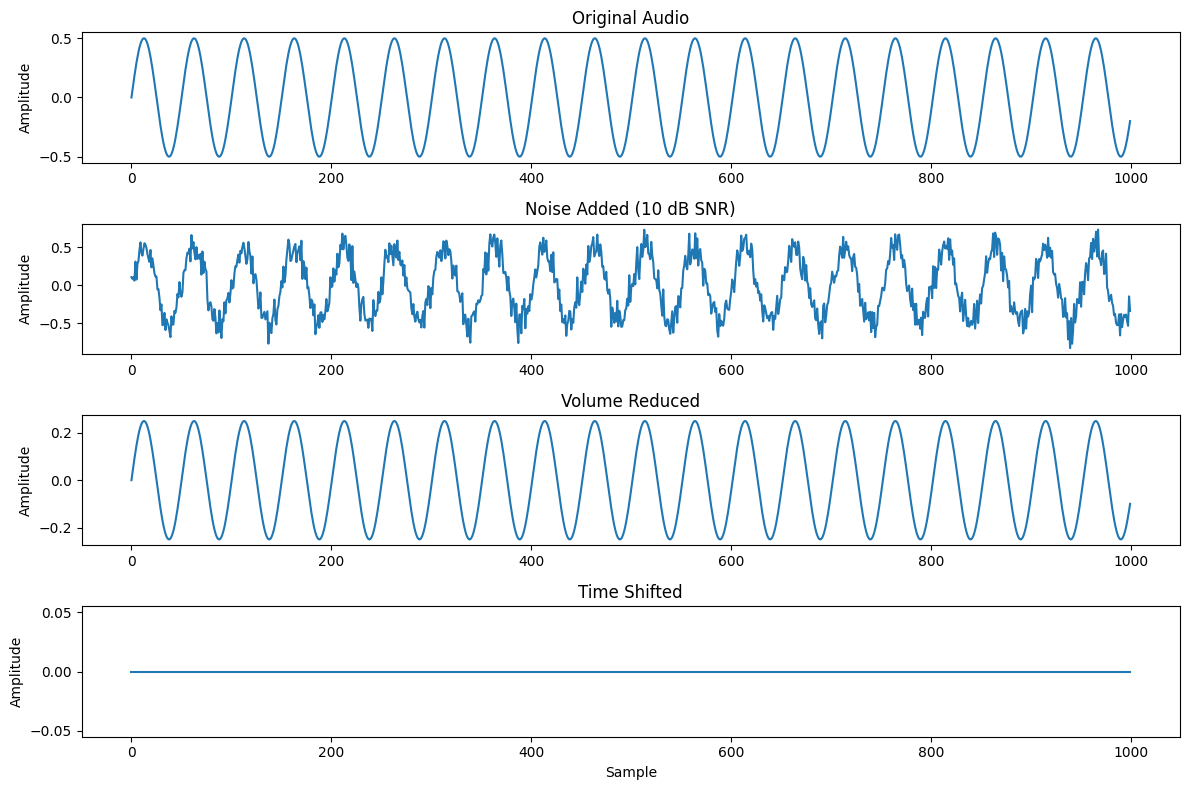

AUDIO AUGMENTATION TEST PASSED!


In [ ]:

# TEST AUDIO AUGMENTATION

t = np.arange(NUM_SAMPLES) / SAMPLE_RATE

# Generate a 440 Hz test tone
test_audio = (
    0.5 * np.sin(2 * np.pi * 440 * t)
).astype(np.float32)

noisy_audio = add_noise(test_audio, snr_db=10)
volume_audio = change_volume(test_audio, factor=0.5)
shifted_audio = time_shift(test_audio, shift_samples=4000)

# Verify output lengths
assert len(noisy_audio) == NUM_SAMPLES
assert len(volume_audio) == NUM_SAMPLES
assert len(shifted_audio) == NUM_SAMPLES

# Plot the first 1000 samples
plt.figure(figsize=(12, 8))

signals = [
    (test_audio, "Original Audio"),
    (noisy_audio, "Noise Added (10 dB SNR)"),
    (volume_audio, "Volume Reduced"),
    (shifted_audio, "Time Shifted")
]

for i, (signal, title) in enumerate(signals):
    plt.subplot(4, 1, i + 1)
    plt.plot(signal[:1000])
    plt.title(title)
    plt.ylabel("Amplitude")

plt.xlabel("Sample")
plt.tight_layout()
plt.show()

print("AUDIO AUGMENTATION TEST PASSED!")